In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Electricity Generation Across Countries — 2024

## Introduction

Electricity generation can be compared in two different ways:

Total generation shows a country’s contribution to global electricity production.

Generation per person adjusts for population and makes countries of different sizes easier to compare.

This analysis explores both perspectives using 2024 data. It addresses three questions:

**Which countries generate the most electricity in total?**

**Which countries generate the most electricity per person?**

**How are total generation and generation per person related?**

Units: Total electricity generation is measured in kilowatt-hours (kWh) and displayed as terawatt-hours (TWh), where 1 TWh equals 1 billion kWh.

## Data Preparation

The electricity dataset contains annual generation figures from 1985 to 2024. For this analysis, I selected the country identifier, country name, and 2024 electricity generation.

The 2024 population data was then merged with the electricity data using the standardized country code (geo). Electricity generation per person was calculated as:

Total electricity generation (kWh)/ Population

Regional classifications were also added so countries could be distinguished by world region in the final visualization.

## Question 1: Which Countries Generate the Most Electricity?

In [2]:
df = pd.read_csv("Downloads/electricity_generation_total.csv")
df.head()

,geo,name,1985,1986,1987,1988,1989,1990,1991,1992,...,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,are,UAE,1.218500e+10,1.281500e+10,1.365800e+10,1.484000e+10,1.561200e+10,17081000000,1.722200e+10,1.868900e+10,...,1.273830e+11,1.296130e+11,1.345687e+11,1.360143e+11,1.384541e+11,1.373104e+11,1.490529e+11,155438500000,167532700000,1.772539e+11
1,arg,Argentina,4.530373e+10,4.902219e+10,5.211528e+10,5.249952e+10,5.086281e+10,51004890000,5.385427e+10,5.610710e+10,...,1.454216e+11,1.471928e+11,1.456184e+11,1.467739e+11,1.395299e+11,1.446428e+11,1.531519e+11,145619000000,148571990000,1.525013e+11
2,aus,Australia,1.236730e+11,1.295270e+11,1.358150e+11,1.433740e+11,1.514330e+11,155653500000,1.579635e+11,1.614005e+11,...,2.539844e+11,2.582187e+11,2.589671e+11,2.626320e+11,2.659002e+11,2.651621e+11,2.674523e+11,272921740000,273105500000,2.816286e+11
3,aut,Austria,4.374200e+10,4.397700e+10,4.968800e+10,4.814900e+10,4.915500e+10,49296000000,5.127025e+10,5.098482e+10,...,6.551279e+10,6.851316e+10,7.132441e+10,6.861805e+10,7.423430e+10,7.255631e+10,7.088654e+10,69193240000,74459410000,8.320434e+10
4,aze,Azerbaijan,2.070200e+10,2.154200e+10,2.290900e+10,2.357200e+10,2.330000e+10,23152000000,2.344950e+10,1.976260e+10,...,2.468760e+10,2.495290e+10,2.432090e+10,2.522920e+10,2.607290e+10,2.583910e+10,2.788780e+10,29039800000,29305900000,2.839614e+10


In [3]:
df_2024 = df[["geo", "name", "2024"]]
df_2024.head()

,geo,name,2024
0,are,UAE,1.772539e+11
1,arg,Argentina,1.525013e+11
2,aus,Australia,2.816286e+11
3,aut,Austria,8.320434e+10
4,aze,Azerbaijan,2.839614e+10


In [4]:
df_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   geo     77 non-null     object 
 1   name    77 non-null     object 
 2   2024    77 non-null     float64
dtypes: float64(1), object(2)
memory usage: 1.9+ KB


In [5]:
top10 = df_2024.sort_values("2024", ascending=False).head(10).reset_index(drop=True)

In [6]:
top10

,geo,name,2024
0,chn,China,1.008688e+13
1,usa,USA,4.634790e+12
2,ind,India,2.030212e+12
3,rus,Russia,1.209320e+12
4,jpn,Japan,1.016389e+12
5,bra,Brazil,7.457151e+11
6,can,Canada,6.367818e+11
7,kor,South Korea,6.253876e+11
8,fra,France,5.613189e+11
9,deu,Germany,4.972877e+11


The countries were ranked by their total electricity generation in 2024. The chart below shows the ten largest electricity-generating countries.

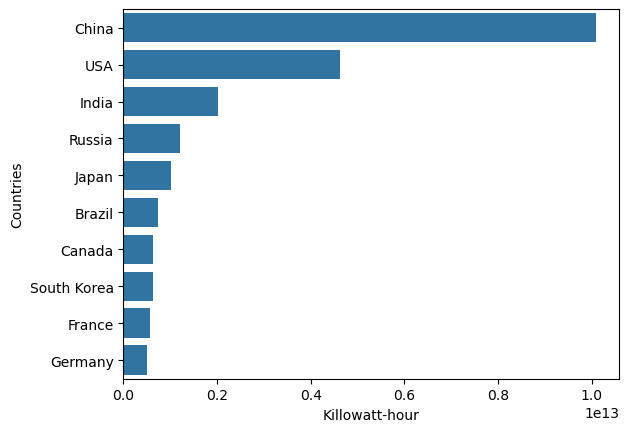

In [7]:
sns.barplot(data=top10, x="2024", y="name");
plt.xlabel("Killowatt-hour")
plt.ylabel("Countries");

### Observation
China generated approximately 10,087 TWh of electricity in 2024. This was more than twice the generation of the United States and nearly five times that of India.

The countries at the top of this ranking are generally large, industrialized, highly populated, or some combination of these characteristics. Therefore, total generation alone does not show how much electricity is generated relative to the number of people living in each country.

## Question 2: Which countries generate the most electricity per person?


In [8]:
pop = pd.read_csv("Downloads/pop.csv")
pop.head()

,geo,name,1800,1801,1802,1803,1804,1805,1806,1807,...,2091,2092,2093,2094,2095,2096,2097,2098,2099,2100
0,afg,Afghanistan,3280000,3280000,3280000,3280000,3280000,3280000,3280000,3280000,...,124110001.0,124854162.0,125589411.0,126306889.0,126990147.0,127647762.0,128305496.0,128964762.0,129616118.0,130216739.0
1,ago,Angola,1567028,1567028,1567028,1567028,1567028,1567028,1567028,1567028,...,138919849.0,140249378.0,141550054.0,142835147.0,144102524.0,145340832.0,146549586.0,147743369.0,148912810.0,150045574.0
2,alb,Albania,400000,401773,403554,405343,407140,408945,410758,412579,...,1344055.0,1324192.0,1304876.0,1286145.0,1268008.0,1250429.0,1233362.0,1216785.0,1200681.0,1184997.0
3,and,Andorra,2654,2654,2654,2654,2654,2654,2654,2654,...,52781.0,52134.0,51484.0,50843.0,50211.0,49586.0,48973.0,48373.0,47791.0,47222.0
4,are,UAE,40153,40153,40153,40153,40153,40153,40153,40153,...,24075187.0,24298127.0,24521988.0,24747048.0,24973506.0,25201603.0,25431504.0,25663508.0,25897696.0,26134299.0


In [9]:
pop_2024 = pop[["geo", "name", "2024"]]
pop_2024.head()

,geo,name,2024
0,afg,Afghanistan,42647492.0
1,ago,Angola,37885849.0
2,alb,Albania,2791765.0
3,and,Andorra,81938.0
4,are,UAE,11027129.0


In [10]:
df_2024 = df_2024.rename(columns={"2024": "electricity_2024"})
pop_2024 = pop_2024.rename(columns={"2024":"population_2024"})

In [11]:
df_2024.head()

,geo,name,electricity_2024
0,are,UAE,1.772539e+11
1,arg,Argentina,1.525013e+11
2,aus,Australia,2.816286e+11
3,aut,Austria,8.320434e+10
4,aze,Azerbaijan,2.839614e+10


In [12]:
pop_2024.head()

,geo,name,population_2024
0,afg,Afghanistan,42647492.0
1,ago,Angola,37885849.0
2,alb,Albania,2791765.0
3,and,Andorra,81938.0
4,are,UAE,11027129.0


In [13]:
electricity_df = df_2024.merge(pop_2024[["geo", "population_2024"]], on="geo")

In [14]:
electricity_df.head()

,geo,name,electricity_2024,population_2024
0,are,UAE,1.772539e+11,11027129.0
1,arg,Argentina,1.525013e+11,45696159.0
2,aus,Australia,2.816286e+11,26713205.0
3,aut,Austria,8.320434e+10,9120813.0
4,aze,Azerbaijan,2.839614e+10,10336577.0


To make comparisons between countries of different population sizes more meaningful, I divided each country’s total electricity generation by its population.

In [15]:
electricity_df["kWh_per_person"] = (electricity_df["electricity_2024"]/electricity_df["population_2024"])

In [16]:
electricity_df.head()

,geo,name,electricity_2024,population_2024,kWh_per_person
0,are,UAE,1.772539e+11,11027129.0,16074.344464
1,arg,Argentina,1.525013e+11,45696159.0,3337.288808
2,aus,Australia,2.816286e+11,26713205.0,10542.671686
3,aut,Austria,8.320434e+10,9120813.0,9122.469675
4,aze,Azerbaijan,2.839614e+10,10336577.0,2747.151209


In [17]:
top_10_per_person = electricity_df.sort_values("kWh_per_person", ascending=False).head(10)

In [24]:
top_10_per_person = electricity_df.sort_values("kWh_per_person", ascending=False).head(10)

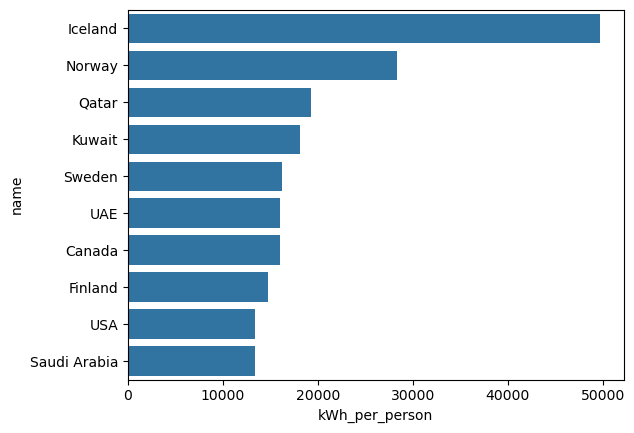

In [18]:
#The following chart ranks the ten countries with the highest electricity generation per person in 2024.
sns.barplot(data=top_10_per_person, x="kWh_per_person", y="name");

### Observation
Adjusting for population substantially changes the ranking. The United States remains among the leading countries, while China and India no longer appear in the top ten.

Several countries with relatively small populations move upward because they generate large quantities of electricity relative to the number of people living there. This demonstrates how a country can be a major electricity producer in absolute terms without having exceptionally high generation per person—and vice versa.

## Total Electricity Generation vs. Generation per Person

In [19]:
regions = pd.read_csv("Downloads/ddf--entities--geo--country.csv")

In [20]:
electricity_df = electricity_df.merge(regions[["country", "world_4region"]],
                    left_on="geo",
                    right_on="country");

In [21]:
electricity_df.head()

,geo,name,electricity_2024,population_2024,kWh_per_person,country,world_4region
0,are,UAE,1.772539e+11,11027129.0,16074.344464,are,asia
1,arg,Argentina,1.525013e+11,45696159.0,3337.288808,arg,americas
2,aus,Australia,2.816286e+11,26713205.0,10542.671686,aus,asia
3,aut,Austria,8.320434e+10,9120813.0,9122.469675,aut,europe
4,aze,Azerbaijan,2.839614e+10,10336577.0,2747.151209,aze,europe


In [22]:
electricity_df = electricity_df.drop(columns="country")

In [23]:
electricity_df.head()

,geo,name,electricity_2024,population_2024,kWh_per_person,world_4region
0,are,UAE,1.772539e+11,11027129.0,16074.344464,asia
1,arg,Argentina,1.525013e+11,45696159.0,3337.288808,americas
2,aus,Australia,2.816286e+11,26713205.0,10542.671686,asia
3,aut,Austria,8.320434e+10,9120813.0,9122.469675,europe
4,aze,Azerbaijan,2.839614e+10,10336577.0,2747.151209,europe


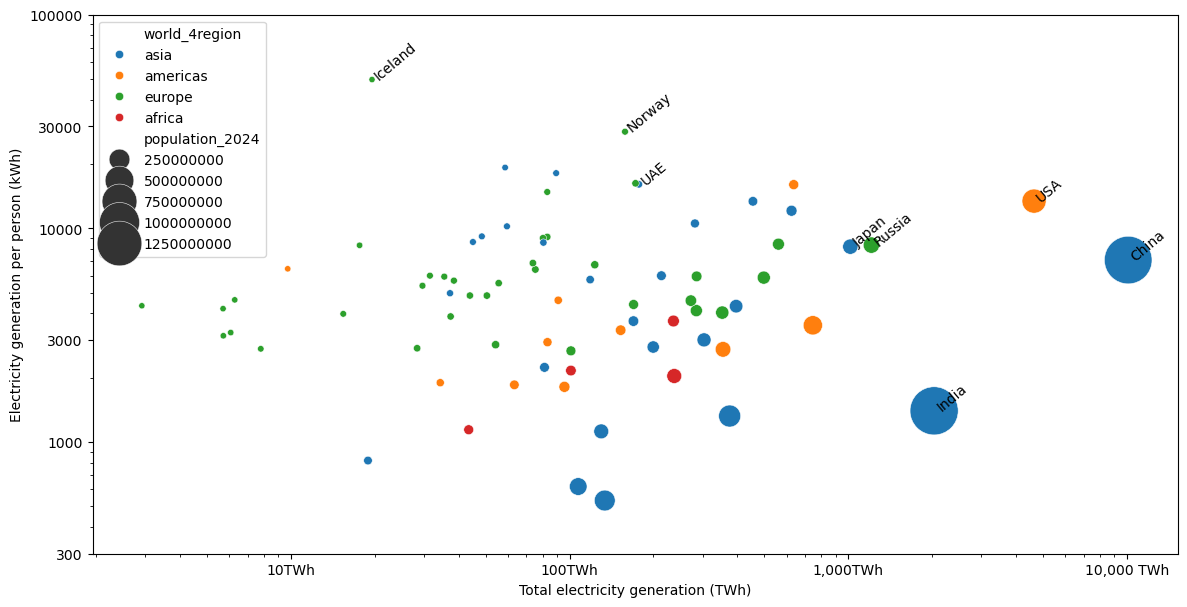

In [24]:
#The scatterplot compares the two measures for every country in the dataset.
plt.figure(figsize=(14, 7))
sns.scatterplot(data=electricity_df, x="electricity_2024", y="kWh_per_person", size="population_2024", sizes=(20,1200),
               hue="world_4region");
plt.xscale("log")
plt.yscale("log");

important_countries = ["China", "USA", "India", "Russia", "Japan", "UAE", "Iceland", "Norway"]
for country in important_countries:
    row = electricity_df[electricity_df["name"] == country]
    
    plt.text(
        row["electricity_2024"].iloc[0],
        row["kWh_per_person"].iloc[0],
        country,
        rotation=40
    )

plt.xticks(
    [1e10, 1e11, 1e12, 1e13],
    ["10TWh", "100TWh", "1,000TWh", "10,000 TWh"]
);
plt.yticks(
    [300, 1000, 3000, 10000, 30000, 100000],
    ["300", "1000", "3000", "10000", "30000", "100000"]
)

plt.xlabel("Total electricity generation (TWh)")
plt.ylabel("Electricity generation per person (kWh)");

Each bubble represents one country:

Horizontal position: Total electricity generation

Vertical position: Electricity generation per person

Bubble size: Population

Bubble color: World region

Both axes use logarithmic scales because the values differ greatly between countries. Logarithmic scaling makes it possible to examine small and large countries on the same chart without the largest observations compressing the remaining data.

### Observation
Countries with the highest total electricity generation do not necessarily generate the most electricity per person.

China and India appear toward the right of the chart because of their enormous total generation. However, their large populations reduce their per-person values. Countries such as Iceland and Norway have much smaller total generation but considerably higher generation per person.

Population therefore helps explain why the rankings produced by the two measures are so different.

Iceland is a particularly noticeable observation because its electricity generation per person is much higher than that of most countries in the dataset. Rather than removing it as an outlier, the logarithmic scale preserves this meaningful observation while making the remaining countries easier to compare.



### Conclusion

This analysis shows that total electricity generation and electricity generation per person answer different questions:

- Total generation identifies the countries that contribute the most electricity in absolute terms.

- Generation per person compares electricity production after accounting for population.

- A high value for one measure does not necessarily imply a high value for the other.

The comparison demonstrates why population should be considered when interpreting country-level totals. Looking at both measures provides a more complete understanding than either measure alone.

## Limitations

- The electricity dataset contains 77 countries, so the results do not represent every country in the world.

- Electricity generation per person is not the same as household electricity access or electricity consumption per person.

- The analysis describes associations and rankings; it does not explain what causes the differences between countries.

- The results depend on the definitions, estimates, and country coverage of the source datasets.

## Data Sources

- Electricity generation data: Gapminder

- Population data: Gapminder

- Country and regional classifications: Gapminder geographic dataset

All calculations and visualizations use data for 2024.